In [1]:
%pip install sherpa-onnx soundfile


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import soundfile as sf

folder = Path.home() / ".cache" / "asr-study" / "sensevoice"
audio_file = folder / "test_wavs" / "ko.wav"

waveform, sample_rate = sf.read(audio_file, dtype="float32")

print("파형 모양:", waveform.shape)
print("샘플링 주파수:", sample_rate, "Hz")
print("음성 길이:", round(len(waveform) / sample_rate, 2), "초")

파형 모양: (73728,)
샘플링 주파수: 16000 Hz
음성 길이: 4.61 초


In [3]:
import sherpa_onnx

# 학습된 모델과 토큰 목록을 읽어 인식기를 준비해요.
recognizer = sherpa_onnx.OfflineRecognizer.from_sense_voice(
    model=str(folder / "model.int8.onnx"),
    tokens=str(folder / "tokens.txt"),
    language="ko",
    provider="cpu",
)

# 첫 셀에서 읽은 음성 한 건을 인식해요.
stream = recognizer.create_stream()
stream.accept_waveform(sample_rate, waveform)
recognizer.decode_stream(stream)

print("인식 결과:", stream.result.text)

인식 결과: 조금만 생각을 하면서 살면 훨씬 편할 거야


In [4]:
%pip install jiwer


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
from jiwer import cer, wer

reference = "조금만 생각을 하면서 살면 훨씬 편할 거야"
recognized = stream.result.text.strip()

def show_score(answer):
    print("기준 문장:", reference)
    print("채점할 문장:", answer)
    print("글자 오류율:", f"{cer(reference.replace(' ', ''), answer.replace(' ', '')):.1%}")
    print("어절 오류율:", f"{wer(reference, answer):.1%}")

show_score(recognized)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
채점할 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
글자 오류율: 0.0%
어절 오류율: 0.0%


In [6]:
practice = recognized.replace("조금만", "조금", 1)
show_score(practice)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
채점할 문장: 조금 생각을 하면서 살면 훨씬 편할 거야
글자 오류율: 5.9%
어절 오류율: 14.3%


In [7]:
import time

audio_seconds = len(waveform) / sample_rate

start = time.perf_counter()  # 초시계 시작
speed_stream = recognizer.create_stream()
speed_stream.accept_waveform(sample_rate, waveform)
recognizer.decode_stream(speed_stream)
text = speed_stream.result.text
elapsed = time.perf_counter() - start  # 걸린 시간

rtf = elapsed / audio_seconds

print("인식 결과:", text)
print(f"음성 길이: {audio_seconds:.3f}초")
print(f"인식 시간: {elapsed:.3f}초")
print(f"RTF: {elapsed:.3f} ÷ {audio_seconds:.3f} = {rtf:.3f}")

인식 결과: 조금만 생각을 하면서 살면 훨씬 편할 거야
음성 길이: 4.608초
인식 시간: 0.615초
RTF: 0.615 ÷ 4.608 = 0.133


In [8]:
import numpy as np

rng = np.random.default_rng(42)
noise = rng.normal(0, 1, size=waveform.shape).astype("float32")

noise_level = 1.0
noisy_waveform = waveform + noise_level * waveform.std() * noise

print("원본 샘플 수:", len(waveform))
print("잡음 섞인 샘플 수:", len(noisy_waveform))

원본 샘플 수: 73728
잡음 섞인 샘플 수: 73728


In [9]:
noisy_stream = recognizer.create_stream()
noisy_stream.accept_waveform(sample_rate, noisy_waveform)
recognizer.decode_stream(noisy_stream)
noisy_text = noisy_stream.result.text

print("원본 음성:", recognized)
print("잡음 음성:", noisy_text)
print()
show_score(noisy_text)

원본 음성: 조금만 생각을 하면서 살면 훨씬 편할 거야
잡음 음성: 누금만 생각을 하면서 되면 훨씬 편할까

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
채점할 문장: 누금만 생각을 하면서 되면 훨씬 편할까
글자 오류율: 23.5%
어절 오류율: 57.1%


In [10]:
import jiwer

result = jiwer.process_words(reference, noisy_text)

print("기준 문장:", reference)
print("잡음 음성의 인식 결과:", noisy_text)
print()
print("다른 어절로 바뀜:", result.substitutions)
print("기준에 있던 어절이 빠짐:", result.deletions)
print("기준에 없던 어절이 추가됨:", result.insertions)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야
잡음 음성의 인식 결과: 누금만 생각을 하면서 되면 훨씬 편할까

다른 어절로 바뀜: 3
기준에 있던 어절이 빠짐: 1
기준에 없던 어절이 추가됨: 0


In [11]:

# CER-> 글자 단위 오류율, WER-> 단어 단위 오류율

import numpy as np
from jiwer import cer, wer

rng = np.random.default_rng(42)
noise = rng.normal(0, 1, size=waveform.shape).astype("float32")
voice_scale = waveform.std()

results = []  # 반복을 시작하기 전에 딱 한 번 빈 목록을 만들어요

for level in [0.00, 0.25, 0.50, 0.75, 1.00, 1.25, 1.50]:
    noisy_wave = waveform + level * voice_scale * noise

    stream = recognizer.create_stream()
    stream.accept_waveform(sample_rate, noisy_wave)
    recognizer.decode_stream(stream)
    text = stream.result.text.strip()

    char_error = cer(reference.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(reference, text)
    results.append((level, char_error * 100, word_error * 100))
    print(f"{level:.2f} | CER {char_error:.1%} | WER {word_error:.1%} | {text}")

print("저장된 결과:", len(results), "개")

0.00 | CER 0.0% | WER 0.0% | 조금만 생각을 하면서 살면 훨씬 편할 거야
0.25 | CER 0.0% | WER 0.0% | 조금만 생각을 하면서 살면 훨씬 편할 거야
0.50 | CER 23.5% | WER 42.9% | 조금만 생각을 하면서 갈면 훨씬 큰날까야
0.75 | CER 23.5% | WER 42.9% | 조금만 생각을 하면서 되면 훨씬 그할까
1.00 | CER 23.5% | WER 57.1% | 누금만 생각을 하면서 되면 훨씬 편할까
1.25 | CER 47.1% | WER 71.4% | 누금만 생각을 하면서 저는 편까요
1.50 | CER 52.9% | WER 71.4% | 누금만 생각을 하면서 저는
저장된 결과: 7 개


In [12]:
#%pip install matplotlib

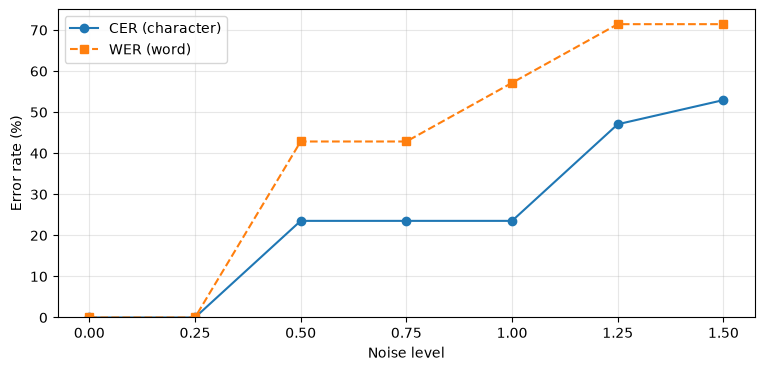

In [13]:
import matplotlib.pyplot as plt

# 저장한 표를 세로로 읽어서 세 열로 나눠요.
levels, cer_values, wer_values = zip(*results)

plt.figure(figsize=(9, 4))
plt.plot(levels, cer_values, "o-", label="CER (character)")
plt.plot(levels, wer_values, "s--", label="WER (word)")

plt.xlabel("Noise level")
plt.ylabel("Error rate (%)")
plt.xticks(levels)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [14]:
from jiwer import cer, wer

def recognize(wave):
    stream = recognizer.create_stream()
    stream.accept_waveform(sample_rate, wave)
    recognizer.decode_stream(stream)
    return stream.result.text.strip()

before_wave = noisy_waveform.copy()
before_text = recognize(before_wave)

print("처리 전 문장:", before_text)
print("처리 전 WER:", f"{wer(reference, before_text):.1%}")

처리 전 문장: 누금만 생각을 하면서 되면 훨씬 편할까
처리 전 WER: 57.1%


In [15]:
import numpy as np

weights = np.array([1/3, 1/3, 1/3], dtype=np.float32)
after_wave = np.convolve(before_wave, weights, mode="same")

print("처리 전 샘플 수:", len(before_wave))
print("처리 후 샘플 수:", len(after_wave))

처리 전 샘플 수: 73728
처리 후 샘플 수: 73728


In [16]:
after_text = recognize(after_wave)

print("기준 문장:", reference)
print()

for label, text in [("처리 전", before_text), ("처리 후", after_text)]:
    char_error = cer(reference.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(reference, text)

    print(f"{label} | CER {char_error:.1%} | WER {word_error:.1%}")
    print(text)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야

처리 전 | CER 23.5% | WER 57.1%
누금만 생각을 하면서 되면 훨씬 편할까
처리 후 | CER 35.3% | WER 71.4%
누금만 생각을 하는데 보면 훨씬 편할까


In [17]:
import numpy as np
from scipy.signal import stft, istft

# 400개씩 보고 160개씩 이동하므로 이웃한 프레임은 240개가 겹쳐요.
_, _, spectrum = stft(before_wave, fs=sample_rate, nperseg=400, noverlap=240)
magnitude = np.abs(spectrum)

# 각 프레임의 세기를 구하고, 가장 조용한 20%를 골라요.
frame_power = (magnitude ** 2).mean(axis=0)
quiet_frames = frame_power <= np.quantile(frame_power, 0.20)

# 조용한 프레임들의 평균을 내서 주파수별 잡음 크기를 추정해요.
noise_profile = magnitude[:, quiet_frames].mean(axis=1, keepdims=True)

print("전체 프레임 수:", magnitude.shape[1])
print("잡음 추정에 쓴 프레임 수:", quiet_frames.sum())

전체 프레임 수: 462
잡음 추정에 쓴 프레임 수: 93


In [18]:
gain = 1 - noise_profile / np.maximum(magnitude, 1e-10)
gain = np.clip(gain, 0.10, 1.0)
cleaned_spectrum = spectrum * gain

_, spectral_wave = istft(cleaned_spectrum, fs=sample_rate, nperseg=400, noverlap=240)
spectral_wave = spectral_wave[:len(before_wave)].astype(np.float32)

print("처리 전후 샘플 수가 같은가?", len(before_wave) == len(spectral_wave))

처리 전후 샘플 수가 같은가? True


In [19]:
def subtract_noise(alpha):
    if alpha == 0:
        return before_wave

    gain = 1 - alpha * noise_profile / np.maximum(magnitude, 1e-10)
    gain = np.clip(gain, 0.10, 1.0)

    _, wave = istft(spectrum * gain, fs=sample_rate, nperseg=400, noverlap=240)
    return wave[:len(before_wave)].astype(np.float32)

In [20]:
from jiwer import cer, wer

strength_results = []
print("세기 | CER | WER | 인식 문장")

for alpha in [0.00, 0.25, 0.50, 0.75, 1.00, 1.25, 1.50]:
    wave = subtract_noise(alpha)
    text = recognize(wave)

    char_error = cer(reference.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(reference, text)

    strength_results.append((alpha, char_error, word_error, text))
    print(f"{alpha:.2f} | {char_error:.1%} | {word_error:.1%} | {text}")

세기 | CER | WER | 인식 문장
0.00 | 23.5% | 57.1% | 누금만 생각을 하면서 되면 훨씬 편할까
0.25 | 41.2% | 71.4% | 누금만 생각을 하는데 보면 훨씬 그할까
0.50 | 35.3% | 71.4% | 누금만 생각을 하는데 보면 훨씬 편할까
0.75 | 35.3% | 71.4% | 누금만 생각을 하는데 보면 훨씬 편할까요
1.00 | 41.2% | 71.4% | 누금만 생각을 게 보면 훨씬 편할까
1.25 | 47.1% | 71.4% | 누금만 생각을 게 분명 훨씬 편할까
1.50 | 47.1% | 71.4% | 누금만 생각을 게 저는 훨씬 편할까


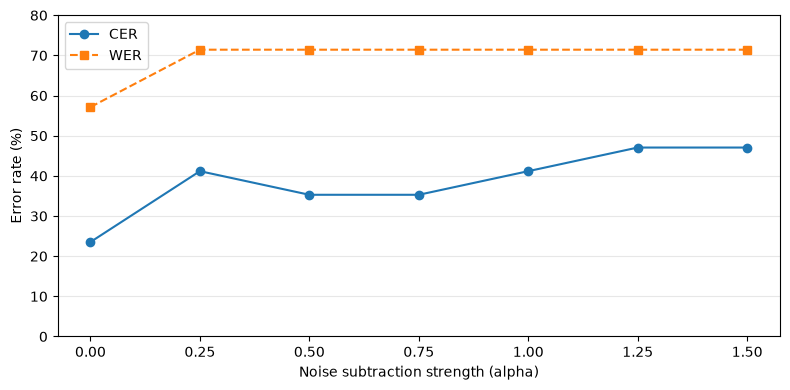

In [21]:
import matplotlib.pyplot as plt

strengths = []
cer_percent = []
wer_percent = []

for alpha, char_error, word_error, text in strength_results:
    strengths.append(alpha)
    cer_percent.append(char_error * 100)  # 0.235를 23.5%로 표시
    wer_percent.append(word_error * 100)

plt.figure(figsize=(8, 4))
plt.plot(strengths, cer_percent, "o-", label="CER")
plt.plot(strengths, wer_percent, "s--", label="WER")

plt.xlabel("Noise subtraction strength (alpha)")
plt.ylabel("Error rate (%)")
plt.xticks(strengths)
plt.ylim(0, 80)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 조용한 순간의 볼륨 낮추기

import numpy as np
from scipy.ndimage import uniform_filter1d

# 25ms씩 살펴보며 소리의 세기를 구해요.
window = round(0.025 * sample_rate)
local_power = uniform_filter1d(             # local_power = 순간 주변의 소리 세기 구함 
    before_wave.astype("float64") ** 2, size=window, mode="nearest"
)

# 전체에서 세기가 하위 20%인 지점을 배경 잡음의 기준으로 삼아요.
noise_power = np.quantile(local_power, 0.20)

# 배경보다 큰 소리는 많이 남기고, 작은 소리는 볼륨을 낮춰요.
gain = 1 - noise_power / np.maximum(local_power, 1e-12)
gain = np.clip(gain, 0.30, 1.00)
volume_wave = (before_wave * gain).astype("float32")        # volume_wave = 볼륨을 조절한 새 파형 

print(f"가장 작게 남긴 볼륨: {gain.min():.0%}")
print(f"가장 크게 남긴 볼륨: {gain.max():.0%}")

가장 작게 남긴 볼륨: 30%
가장 크게 남긴 볼륨: 93%


In [ ]:
from scipy.signal import butter, sosfiltfilt        # butter = 어떤 주파수를 얼마나 줄일지 규칙을 만드는 함수, sosfiltfilt = 실제 소리에 적용하는 함수

lowpass = butter(4, 4000, fs=sample_rate, btype="lowpass", output="sos")
lowpass_wave = sosfiltfilt(lowpass, before_wave).astype("float32")

In [24]:
from jiwer import cer, wer

print("기준 문장:", reference)

for name, wave in [
    ("처리 전", before_wave),
    ("조용한 순간의 볼륨 낮추기", volume_wave),
    ("높은 주파수 줄이기", lowpass_wave),
]:
    text = recognize(wave)
    char_error = cer(reference.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(reference, text)
    print(f"\n{name} | CER {char_error:.1%} | WER {word_error:.1%}")
    print(text)

기준 문장: 조금만 생각을 하면서 살면 훨씬 편할 거야

처리 전 | CER 23.5% | WER 57.1%
누금만 생각을 하면서 되면 훨씬 편할까

조용한 순간의 볼륨 낮추기 | CER 47.1% | WER 85.7%
누금만 생각을 게 되면 훨씬할까요

높은 주파수 줄이기 | CER 35.3% | WER 71.4%
누금만 생각을 하는데 보면 훨씬 편할까


In [25]:
from pathlib import Path
import soundfile as sf

folder = Path.home() / ".cache" / "asr-study" / "zeroth"
clip_id = "105_003_0029"

clean, sr = sf.read(folder / f"{clip_id}.flac", dtype="float32")
answer = (folder / f"{clip_id}.txt").read_text(encoding="utf-8").strip()

print("기준 문장:", answer)
print("샘플링 주파수:", sr)

기준 문장: 몬터규는 자녀들이 사랑을 제대로 못 받고 크면 매우 심각한 결과가 초래된다는 결론을 내렸습니다
샘플링 주파수: 16000


In [ ]:
import numpy as np

rng = np.random.default_rng(42)
noise = rng.normal(0, 1, size=clean.shape).astype("float32")  # 파형의 각 숫자에 하나씩 더할 잡음 숫자를 만드는 코드, size=clean.shape으로 개수가 맞도록 clean과 같은 모양으로 잡음 생성 
noisy = clean + clean.std() * noise     # 원래 소리 + 잡음, clean.std() = 원래 소리의 표준편차, noise = 잡음, clean.std() * noise = 잡음의 세기

In [ ]:
from scipy.ndimage import uniform_filter1d
from scipy.signal import butter, sosfiltfilt

window = round(0.025 * sr)      # 25ms씩 살펴보며 소리의 세기를 구해요.
power = uniform_filter1d(noisy.astype("float64") ** 2, size=window, mode="nearest")
background = np.quantile(power, 0.20)
gain = np.clip(1 - background / np.maximum(power, 1e-12), 0.30, 1.00)
quieter = (noisy * gain).astype("float32")

lowpass = butter(4, 4000, fs=sr, btype="lowpass", output="sos")
filtered = sosfiltfilt(lowpass, noisy).astype("float32")

In [28]:
from jiwer import cer, wer

versions = [("처리 전", noisy), ("조용한 순간 줄이기", quieter), ("높은 주파수 줄이기", filtered)]

for name, wave in versions:
    text = recognize(wave)
    char_error = cer(answer.replace(" ", ""), text.replace(" ", ""))
    word_error = wer(answer, text)
    print(f"{name} | CER {char_error:.1%} | WER {word_error:.1%}")
    print(text)

처리 전 | CER 15.0% | WER 30.8%
몬토글는 자녀들이 사랑을을 제대로 못 받고 크 매우 심각한 결과가 해해된다는 결론을 내렸습니다
조용한 순간 줄이기 | CER 22.5% | WER 53.8%
몬포수는 자녀들이 사랑을을 제대로 못 받고 크 늘 심각한 결과가 세해 된다는 결론을 내었습니다
높은 주파수 줄이기 | CER 12.5% | WER 23.1%
몬토글는 자녀들이 사랑을 제대로 못 받고 크 매우 심각한 결과가 손해된다는 결론을 내렸습니다


In [29]:
from pathlib import Path

folder = Path.home() / ".cache" / "asr-study" / "zeroth"
clip_ids = ["105_003_0029", "137_003_0029"]

def read_answer(clip_id):
    return (folder / f"{clip_id}.txt").read_text(encoding="utf-8").strip()

answer = read_answer(clip_ids[0])
print("두 문장이 같은가?", answer == read_answer(clip_ids[1]))
print("기준 문장:", answer)

두 문장이 같은가? True
기준 문장: 몬터규는 자녀들이 사랑을 제대로 못 받고 크면 매우 심각한 결과가 초래된다는 결론을 내렸습니다


In [30]:
import numpy as np
from scipy.ndimage import uniform_filter1d
from scipy.signal import butter, sosfiltfilt

def make_versions(clean, sr):
    rng = np.random.default_rng(42)
    noise = rng.normal(0, 1, size=clean.shape).astype("float32")
    noisy = clean + clean.std() * noise

    window = round(0.025 * sr)
    power = uniform_filter1d(noisy.astype("float64") ** 2, size=window, mode="nearest")
    background = np.quantile(power, 0.20)
    gain = np.clip(1 - background / np.maximum(power, 1e-12), 0.30, 1.00)
    quieter = (noisy * gain).astype("float32")

    lowpass = butter(4, 4000, fs=sr, btype="lowpass", output="sos")
    filtered = sosfiltfilt(lowpass, noisy).astype("float32")

    return {"처리 전": noisy, "조용한 순간 줄이기": quieter, "높은 주파수 줄이기": filtered}

In [31]:
import soundfile as sf
from jiwer import cer, wer

for clip_id in clip_ids:
    clean, sr = sf.read(folder / f"{clip_id}.flac", dtype="float32")
    versions = make_versions(clean, sr)
    print(f"\n녹음 {clip_id}")

    for name, wave in versions.items():
        text = recognize(wave)
        char_error = cer(answer.replace(" ", ""), text.replace(" ", ""))
        word_error = wer(answer, text)
        print(f"{name} | CER {char_error:.1%} | WER {word_error:.1%}")
        print(text)


녹음 105_003_0029
처리 전 | CER 15.0% | WER 30.8%
몬토글는 자녀들이 사랑을을 제대로 못 받고 크 매우 심각한 결과가 해해된다는 결론을 내렸습니다
조용한 순간 줄이기 | CER 22.5% | WER 53.8%
몬포수는 자녀들이 사랑을을 제대로 못 받고 크 늘 심각한 결과가 세해 된다는 결론을 내었습니다
높은 주파수 줄이기 | CER 12.5% | WER 23.1%
몬토글는 자녀들이 사랑을 제대로 못 받고 크 매우 심각한 결과가 손해된다는 결론을 내렸습니다

녹음 137_003_0029
처리 전 | CER 12.5% | WER 15.4%
옹소종은 자녀들이 사랑을 제대로 못 받고 크면 매우 심각한 결과가 틀래된다는 결론을 내렸습니다
조용한 순간 줄이기 | CER 15.0% | WER 38.5%
문세중은 자녀들이 사랑을 제대로 못받고 크면 매우 심각한 결과가 흐래된다는 결론는 내렸습니다
높은 주파수 줄이기 | CER 20.0% | WER 15.4%
옹소중은 자녀들이 사랑을 제대로 못 받고 크면 매우 심각한 결과가 틀려든는 결론을 내렸습니다


In [32]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["Before", "Quiet down", "Low-pass"]

cer_105 = [15.0, 22.5, 12.5]
cer_137 = [12.5, 15.0, 20.0]
wer_105 = [30.8, 53.8, 23.1]
wer_137 = [15.4, 38.5, 15.4]

x = np.arange(len(methods))
width = 0.36

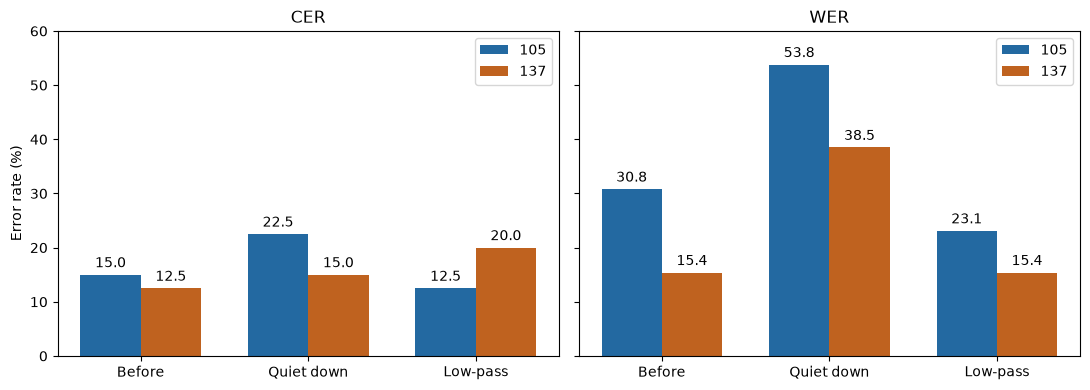

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)  # 그래프 두 칸을 같은 세로 눈금으로 준비해요.

def draw(ax, title, scores_105, scores_137):  # 그래프 한 칸을 그리는 방법이에요.
    bars_105 = ax.bar(x - width / 2, scores_105, width, color="#2369A1", label="105")
    bars_137 = ax.bar(x + width / 2, scores_137, width, color="#BF621F", label="137")

    ax.bar_label(bars_105, fmt="%.1f", padding=3)  # 파란 막대 위에 숫자를 적어요.
    ax.bar_label(bars_137, fmt="%.1f", padding=3)  # 주황 막대 위에도 숫자를 적어요.
    ax.set_xticks(x, labels=methods)              # 0, 1, 2 자리에 처리 방법 이름을 붙여요.
    ax.set_title(title)                           # 이 칸의 제목을 적어요.
    ax.set_ylim(0, 60)                            # 세로축은 0%부터 60%까지 보여줘요.
    ax.legend()                                   # 어느 색이 어느 화자인지 표시해요.

draw(axes[0], "CER", cer_105, cer_137)  # 왼쪽 칸에 두 사람의 글자 오류율을 그려요.
draw(axes[1], "WER", wer_105, wer_137)  # 오른쪽 칸에 두 사람의 어절 오류율을 그려요.
axes[0].set_ylabel("Error rate (%)")   # 세로축의 단위가 퍼센트라고 적어요.
fig.tight_layout()                    # 글자와 그림 사이의 간격을 정리해요.
plt.show()                            # 완성한 그림을 화면에 보여줘요.

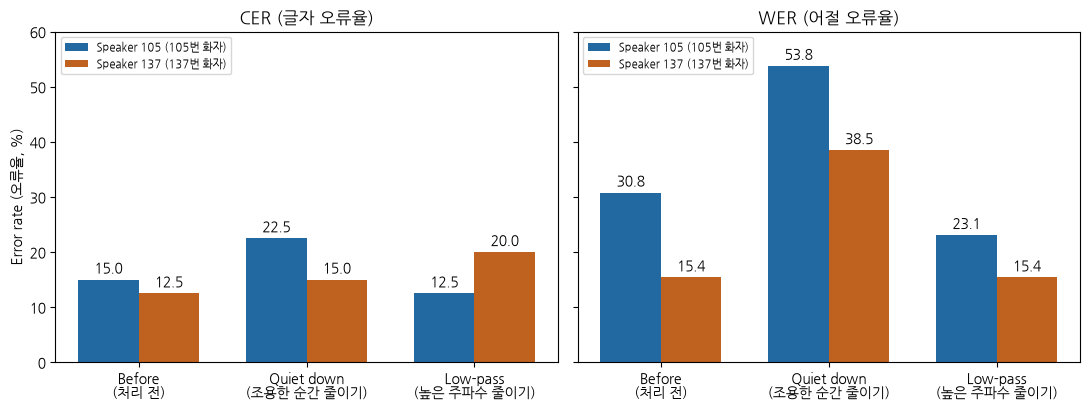

In [ ]:
plt.rcParams["font.family"] = "NanumGothic"  # 실습 서버에 있는 한글 글꼴 사용

methods = [
    "Before\n(처리 전)",
    "Quiet down\n(조용한 순간 줄이기)",
    "Low-pass\n(높은 주파수 줄이기)",
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

draw(axes[0], "CER (글자 오류율)", cer_105, cer_137)
draw(axes[1], "WER (어절 오류율)", wer_105, wer_137)

for ax in axes:
    ax.legend(["Speaker 105 (105번 화자)", "Speaker 137 (137번 화자)"],
              loc="upper left", fontsize=8)

axes[0].set_ylabel("Error rate (오류율, %)")
fig.tight_layout()
plt.show()